In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/flight_delay_data/19_20_cleaned_data.csv")
print(df.info())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1165231 entries, 0 to 1165230
Data columns (total 15 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   DAY_OF_MONTH       1165231 non-null  int64  
 1   DAY_OF_WEEK        1165231 non-null  int64  
 2   OP_CARRIER         1165231 non-null  object 
 3   TAIL_NUM           1165231 non-null  object 
 4   OP_CARRIER_FL_NUM  1165231 non-null  int64  
 5   ORIGIN             1165231 non-null  object 
 6   DEST               1165231 non-null  object 
 7   DEP_TIME           1165231 non-null  float64
 8   DEP_DEL15          1165231 non-null  int64  
 9   DEP_TIME_BLK       1165231 non-null  object 
 10  ARR_TIME           1165231 non-null  float64
 11  ARR_DEL15          1165231 non-null  int64  
 12  DISTANCE           1165231 non-null  float64
 13  IS_WEEKEND         1165231 non-null  int64  
 14  IS_DELAYED         1165231 non-null  int64  
dtypes: float64(3), int64(7), object(

In [ ]:
df = df.drop(columns=[
    "TAIL_NUM", "OP_CARRIER_FL_NUM",
    "ORIGIN_AIRPORT_SEQ_ID", "DEST_AIRPORT_SEQ_ID"
], errors='ignore') #drop unnecessary columns, maybe not airport seq ids ???

df = df.dropna(subset=["DEP_TIME", "ARR_TIME", "IS_DELAYED"]) #drop rows which miss critical data

In [ ]:
y = df["IS_DELAYED"]
X = df.drop(columns=["IS_DELAYED", "DEP_DEL15", "ARR_DEL15"])

In [ ]:
X = X.drop(columns=["ROUTE"], errors='ignore')

#encode categorical variables with one-hot encoding

X = pd.get_dummies(
    X,
    columns=["OP_CARRIER", "ORIGIN", "DEST", "DEP_TIME_BLK"], #if route is used, include it here
    drop_first=True
)

#drop route column



In [ ]:
#scaling
%pip install scikit-learn
from sklearn.preprocessing import StandardScaler

num_cols = ["DAY_OF_MONTH", "DAY_OF_WEEK", "DEP_TIME", "ARR_TIME", "DISTANCE", "IS_WEEKEND"]
scaler = StandardScaler()
X[num_cols] = scaler.fit_transform(X[num_cols])

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
print("Shape:", X.shape)
print("Approx memory GB:", X.memory_usage(deep=True).sum() / 1e9)

Shape: (1165231, 744)
Approx memory GB: 0.915871698


In [ ]:
#i dont run this for now but if model requires higher memory, use sparse matrix
"""

from scipy import sparse
from sklearn.linear_model import LogisticRegression

X_sparse = sparse.csr_matrix(X)  # keeps only non-zero entries
logit = LogisticRegression(solver='saga', max_iter=200, n_jobs=-1)
logit.fit(X_sparse, y)
"""

"\n\nfrom scipy import sparse\nfrom sklearn.linear_model import LogisticRegression\n\nX_sparse = sparse.csr_matrix(X)  # keeps only non-zero entries\nlogit = LogisticRegression(solver='saga', max_iter=200, n_jobs=-1)\nlogit.fit(X_sparse, y)\n"

In [ ]:
from sklearn.linear_model import LogisticRegression

logit = LogisticRegression(max_iter=200, solver='lbfgs',n_jobs=1)
logit.fit(X_train, y_train)

LogisticRegression(max_iter=200, n_jobs=1)

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = logit.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8504078576424499

Confusion Matrix:
 [[187382    162]
 [ 34700  10803]]

Classification Report:
               precision    recall  f1-score   support

           0       0.84      1.00      0.91    187544
           1       0.99      0.24      0.38     45503

    accuracy                           0.85    233047
   macro avg       0.91      0.62      0.65    233047
weighted avg       0.87      0.85      0.81    233047



In [ ]:
y_prob = logit.predict_proba(X_test)[:, 1]

In [ ]:
import numpy as np

coef_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logit.coef_[0]
}).sort_values(by="Coefficient", ascending=False)

print(coef_table.head(15))

        Feature  Coefficient
2      DEP_TIME     6.104802
67   ORIGIN_BQN     2.328936
287  ORIGIN_PSE     2.299014
267  ORIGIN_PAE     1.009540
194  ORIGIN_JLN     0.972539
178  ORIGIN_IAG     0.918432
37   ORIGIN_APN     0.907376
128  ORIGIN_ESC     0.867986
382    DEST_ADQ     0.839707
557    DEST_LBE     0.805272
38   ORIGIN_ART     0.787432
484    DEST_EWR     0.775094
269  ORIGIN_PBG     0.756992
564    DEST_LGA     0.746365
419    DEST_BQN     0.689657


Computing metrics for 201 thresholds (optimized from 233047)...


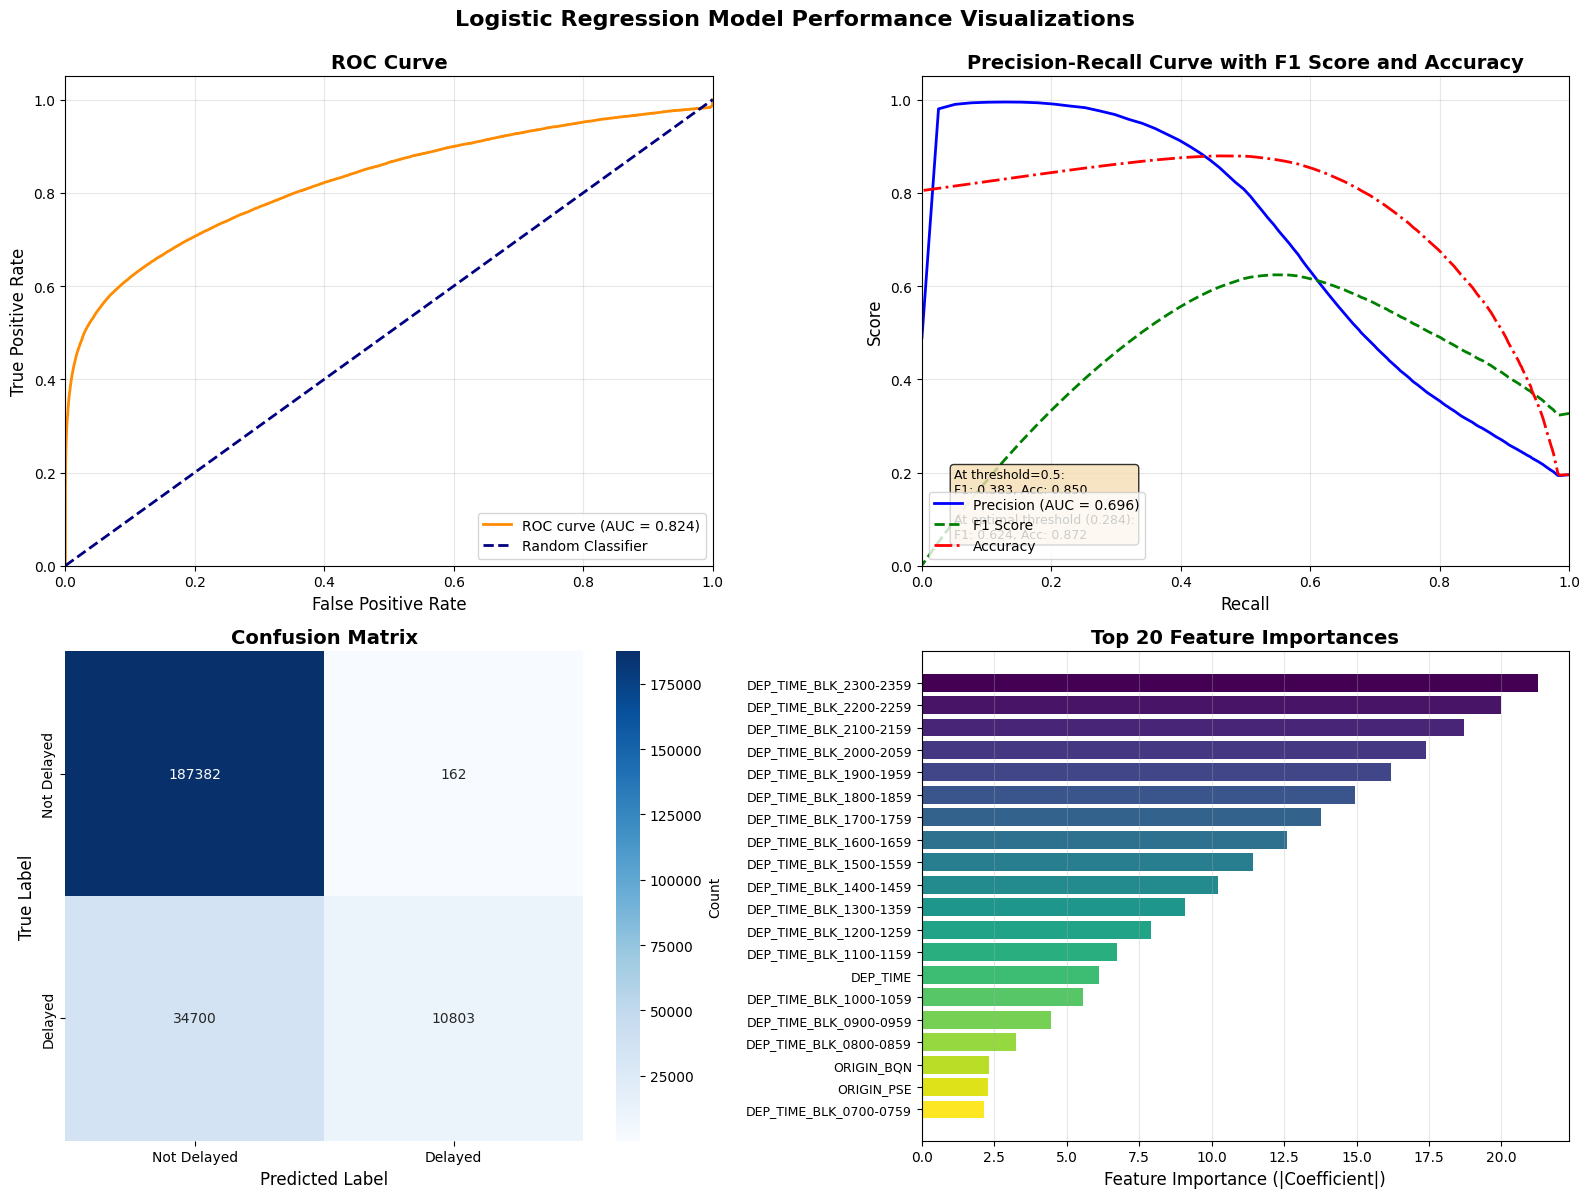


Model Performance Summary:
ROC AUC: 0.8244
PR AUC: 0.6963

At Default Threshold (0.5):
  F1 Score: 0.3826
  Accuracy: 0.8504

At Optimal Threshold (0.284):
  F1 Score: 0.6241
  Accuracy: 0.8720


In [ ]:
# Model Visualizations: ROC Curve, PR Curve, Confusion Matrix, Feature Importance
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, precision_recall_curve, roc_auc_score, f1_score, accuracy_score
import numpy as np

# Set style
plt.style.use('default')
sns.set_palette("husl")

# Create figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. ROC Curve
fpr, tpr, thresholds_roc = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

axes[0, 0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
axes[0, 0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
axes[0, 0].set_xlim([0.0, 1.0])
axes[0, 0].set_ylim([0.0, 1.05])
axes[0, 0].set_xlabel('False Positive Rate', fontsize=12)
axes[0, 0].set_ylabel('True Positive Rate', fontsize=12)
axes[0, 0].set_title('ROC Curve', fontsize=14, fontweight='bold')
axes[0, 0].legend(loc="lower right")
axes[0, 0].grid(alpha=0.3)

# 2. Precision-Recall Curve with F1 Score and Accuracy Curves
precision, recall, thresholds_pr = precision_recall_curve(y_test, y_prob)
pr_auc = auc(recall, precision)

# Calculate F1 score and accuracy at default threshold (0.5)
f1_default = f1_score(y_test, y_pred)
accuracy_default = accuracy_score(y_test, y_pred)

# Calculate F1 scores and accuracy at different thresholds
# Optimize: Sample thresholds to speed up computation (use every Nth threshold or max 200 points)
if len(thresholds_pr) > 200:
    step = max(1, len(thresholds_pr) // 200)
    sampled_indices = np.arange(0, len(thresholds_pr), step)
    sampled_thresholds = thresholds_pr[sampled_indices]
    sampled_recall = recall[sampled_indices]
    sampled_precision = precision[sampled_indices]
else:
    sampled_thresholds = thresholds_pr
    sampled_precision = precision
    sampled_recall = recall

f1_scores = []
accuracy_scores = []
print(f"Computing metrics for {len(sampled_thresholds)} thresholds (optimized from {len(thresholds_pr)})...")
for threshold in sampled_thresholds:
    y_pred_thresh = (y_prob >= threshold).astype(int)
    f1_scores.append(f1_score(y_test, y_pred_thresh))
    accuracy_scores.append(accuracy_score(y_test, y_pred_thresh))

# Find optimal threshold (max F1 score) from sampled thresholds
optimal_idx = np.argmax(f1_scores)
optimal_threshold = sampled_thresholds[optimal_idx]
f1_optimal = f1_scores[optimal_idx]
y_pred_optimal = (y_prob >= optimal_threshold).astype(int)
accuracy_optimal = accuracy_score(y_test, y_pred_optimal)

# Plot all curves on the same graph (x-axis: Recall, y-axis: Score)
axes[0, 1].plot(sampled_recall, sampled_precision, color='blue', lw=2, label=f'Precision (AUC = {pr_auc:.3f})', linestyle='-')
axes[0, 1].plot(sampled_recall, f1_scores, color='green', lw=2, label='F1 Score', linestyle='--')
axes[0, 1].plot(sampled_recall, accuracy_scores, color='red', lw=2, label='Accuracy', linestyle='-.')
axes[0, 1].set_xlabel('Recall', fontsize=12)
axes[0, 1].set_ylabel('Score', fontsize=12)
axes[0, 1].set_title('Precision-Recall Curve with F1 Score and Accuracy', fontsize=14, fontweight='bold')
axes[0, 1].legend(loc="lower left", fontsize=10)
axes[0, 1].grid(alpha=0.3)
axes[0, 1].set_xlim([0.0, 1.0])
axes[0, 1].set_ylim([0.0, 1.05])

# Add text box with F1 score and accuracy at key thresholds
textstr = f'At threshold=0.5:\nF1: {f1_default:.3f}, Acc: {accuracy_default:.3f}\n\nAt optimal threshold ({optimal_threshold:.3f}):\nF1: {f1_optimal:.3f}, Acc: {accuracy_optimal:.3f}'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
axes[0, 1].text(0.05, 0.05, textstr, transform=axes[0, 1].transAxes, fontsize=9,
                verticalalignment='bottom', bbox=props)

# 3. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Delayed', 'Delayed'],
            yticklabels=['Not Delayed', 'Delayed'],
            cbar_kws={'label': 'Count'},
            ax=axes[1, 0])
axes[1, 0].set_ylabel('True Label', fontsize=12)
axes[1, 0].set_xlabel('Predicted Label', fontsize=12)
axes[1, 0].set_title('Confusion Matrix', fontsize=14, fontweight='bold')

# 4. Feature Importance (Top 20) - Using absolute coefficient values
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": np.abs(logit.coef_[0])  # Use absolute value of coefficients
}).sort_values(by="Importance", ascending=False)

top_20 = feature_importance.head(20)
colors = plt.cm.viridis(np.linspace(0, 1, len(top_20)))
axes[1, 1].barh(range(len(top_20)), top_20['Importance'].values, color=colors)
axes[1, 1].set_yticks(range(len(top_20)))
axes[1, 1].set_yticklabels(top_20['Feature'].values, fontsize=9)
axes[1, 1].set_xlabel('Feature Importance (|Coefficient|)', fontsize=12)
axes[1, 1].set_title('Top 20 Feature Importances', fontsize=14, fontweight='bold')
axes[1, 1].invert_yaxis()
axes[1, 1].grid(axis='x', alpha=0.3)

plt.suptitle('Logistic Regression Model Performance Visualizations', fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

print(f"\nModel Performance Summary:")
print(f"ROC AUC: {roc_auc:.4f}")
print(f"PR AUC: {pr_auc:.4f}")
print(f"\nAt Default Threshold (0.5):")
print(f"  F1 Score: {f1_default:.4f}")
print(f"  Accuracy: {accuracy_default:.4f}")
print(f"\nAt Optimal Threshold ({optimal_threshold:.3f}):")
print(f"  F1 Score: {f1_optimal:.4f}")
print(f"  Accuracy: {accuracy_optimal:.4f}")



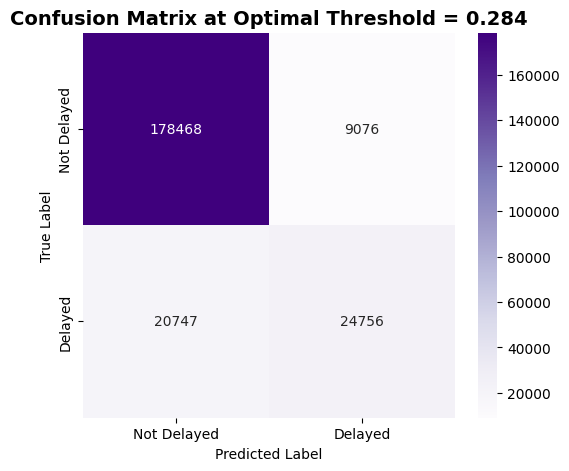

Performance at Optimal Threshold:



,Metric,Value
0,Threshold,0.2840
1,Accuracy,0.8720
2,Precision,0.7317
3,Recall,0.5441
4,F1 Score,0.6241


In [ ]:
# ---------------------------------------------
# Confusion Matrix & Metrics at Optimal Threshold
# ---------------------------------------------
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score
)
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Predictions from optimal threshold
y_pred_optimal = (y_prob >= optimal_threshold).astype(int)

# 2. Compute metrics
accuracy_opt = accuracy_score(y_test, y_pred_optimal)
precision_opt = precision_score(y_test, y_pred_optimal)
recall_opt = recall_score(y_test, y_pred_optimal)
f1_opt = f1_score(y_test, y_pred_optimal)

# 3. Confusion Matrix
cm_opt = confusion_matrix(y_test, y_pred_optimal)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_opt, annot=True, fmt='d', cmap='Purples',
    xticklabels=['Not Delayed', 'Delayed'],
    yticklabels=['Not Delayed', 'Delayed']
)
plt.title(f'Confusion Matrix at Optimal Threshold = {optimal_threshold:.3f}',
          fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# 4. Metrics Schema Table
schema = pd.DataFrame({
    'Metric': ['Threshold', 'Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Value': [optimal_threshold, accuracy_opt, precision_opt, recall_opt, f1_opt]
})

print("Performance at Optimal Threshold:\n")
display(schema.style.format({'Value': '{:.4f}'}))
